In [11]:

# HILL CLIMBING
current_moisture = 45
target_moisture = 60

water_options = [0, 10, 20, 30, 40]

def calculate_score(water):
    predicted_moisture = current_moisture + water * 0.5
    score = -abs(target_moisture - predicted_moisture)
    return score


def hill_climbing():
    current_index = 0

    while True:
        current_water = water_options[current_index]
        current_score = calculate_score(current_water)

        neighbors = []

        if current_index > 0:
            neighbors.append(current_index - 1)

        if current_index < len(water_options) - 1:
            neighbors.append(current_index + 1)

        best_index = current_index

        for index in neighbors:
            if calculate_score(water_options[index]) > calculate_score(water_options[best_index]):
                best_index = index

        if best_index == current_index:
            break

        current_index = best_index

    return water_options[current_index]


best_water = hill_climbing()

print("Current moisture:", current_moisture, "%")
print("Target moisture:", target_moisture, "%")
print("Available water options:", water_options)
print("Recommended water:", best_water, "ml")
print("Predicted moisture:", current_moisture + best_water * 0.5, "%")


Current moisture: 45 %
Target moisture: 60 %
Available water options: [0, 10, 20, 30, 40]
Recommended water: 30 ml
Predicted moisture: 60.0 %


In [12]:

# BAYESIAN INFERENCE

prior_dry = 0.30

sensor_dry_given_dry = 0.90
sensor_dry_given_wet = 0.20

sensor_signal = "LOW MOISTURE"

def bayesian_inference():
    prior_wet = 1 - prior_dry

    probability_signal = (
        sensor_dry_given_dry * prior_dry +
        sensor_dry_given_wet * prior_wet
    )

    posterior_dry = (
        sensor_dry_given_dry * prior_dry
    ) / probability_signal

    return posterior_dry


result = bayesian_inference()

print("Sensor signal:", sensor_signal)
print("Initial dry soil probability:", prior_dry * 100, "%")
print("Updated dry soil probability:", round(result * 100, 2), "%")


Sensor signal: LOW MOISTURE
Initial dry soil probability: 30.0 %
Updated dry soil probability: 65.85 %


In [3]:

# MARKOV DECISION PROCESS (MDP)

prob_dry = result
prob_wet = 1 - result

rewards = {
    "Water": {"Dry": 10, "Wet": -2},
    "Wait": {"Dry": -5, "Wet": 5}
}

transitions = {
    "Water": {
        "Dry": {"Dry": 0.2, "Wet": 0.8},
        "Wet": {"Dry": 0.05, "Wet": 0.95}
    },
    "Wait": {
        "Dry": {"Dry": 0.9, "Wet": 0.1},
        "Wet": {"Dry": 0.1, "Wet": 0.9}
    }
}

def calculate_reward(action):
    reward_dry = rewards[action]["Dry"]
    reward_wet = rewards[action]["Wet"]

    expected_reward = (
        prob_dry * reward_dry +
        prob_wet * reward_wet
    )

    return expected_reward


water_reward = calculate_reward("Water")
wait_reward = calculate_reward("Wait")

if water_reward > wait_reward:
    decision = "Water"
else:
    decision = "Wait"

print("Probability of dry soil:", round(prob_dry * 100, 2), "%")
print("Probability of wet soil:", round(prob_wet * 100, 2), "%")

print("\nExpected reward for Water:", round(water_reward, 2))
print("Expected reward for Wait:", round(wait_reward, 2))

print("\nRecommended action:", decision)


Probability of dry soil: 65.85 %
Probability of wet soil: 34.15 %

Expected reward for Water: 5.9
Expected reward for Wait: -1.59

Recommended action: Water


In [13]:
# MINI GREENHOUSE ASSISTANT

print("=" * 45)
print("       MINI GREENHOUSE ASSISTANT")
print("=" * 45)


current_moisture = 45
target_moisture = 60

sensor_signal = "LOW MOISTURE"

print("\n1. INPUT DATA")
print("Current moisture:", current_moisture, "%")
print("Target moisture:", target_moisture, "%")
print("Sensor signal:", sensor_signal)


prior_dry = 0.30
sensor_dry_given_dry = 0.90
sensor_dry_given_wet = 0.20

def bayesian_inference():
    prior_wet = 1 - prior_dry

    probability_signal = (
        sensor_dry_given_dry * prior_dry +
        sensor_dry_given_wet * prior_wet
    )

    posterior = (
        sensor_dry_given_dry * prior_dry
    ) / probability_signal

    return posterior

prob_dry = bayesian_inference()
prob_wet = 1 - prob_dry

print("\n2. BAYESIAN INFERENCE")
print("Dry soil probability:", round(prob_dry * 100, 2), "%")
print("Wet soil probability:", round(prob_wet * 100, 2), "%")


rewards = {
    "Water": {"Dry": 10, "Wet": -2},
    "Wait": {"Dry": -5, "Wet": 5}
}

transitions = {
    "Water": {
        "Dry": {"Dry": 0.2, "Wet": 0.8},
        "Wet": {"Dry": 0.05, "Wet": 0.95}
    },
    "Wait": {
        "Dry": {"Dry": 0.9, "Wet": 0.1},
        "Wet": {"Dry": 0.1, "Wet": 0.9}
    }
}

state_values = {
    "Dry": -5,
    "Wet": 5
}

gamma = 0.9

def calculate_mdp(action):
    immediate_reward = (
        prob_dry * rewards[action]["Dry"] +
        prob_wet * rewards[action]["Wet"]
    )

    future_value = 0

    for state, probability in [
        ("Dry", prob_dry),
        ("Wet", prob_wet)
    ]:
        for next_state, transition_probability in transitions[action][state].items():
            future_value += (
                probability *
                transition_probability *
                state_values[next_state]
            )

    return immediate_reward + gamma * future_value

water_value = calculate_mdp("Water")
wait_value = calculate_mdp("Wait")

decision = "Water" if water_value > wait_value else "Wait"

print("\n3. MARKOV DECISION PROCESS")
print("Water value:", round(water_value, 2))
print("Wait value:", round(wait_value, 2))
print("Recommended action:", decision)


water_options = [0, 10, 20, 30, 40]

def calculate_score(water):
    predicted = current_moisture + water * 0.5
    return -abs(target_moisture - predicted)

def hill_climbing():
    current_index = 0

    while True:
        neighbors = []

        if current_index > 0:
            neighbors.append(current_index - 1)

        if current_index < len(water_options) - 1:
            neighbors.append(current_index + 1)

        best_index = current_index

        for index in neighbors:
            if calculate_score(water_options[index]) > calculate_score(water_options[best_index]):
                best_index = index

        if best_index == current_index:
            break

        current_index = best_index

    return water_options[current_index]

best_water = hill_climbing()

print("\n4. HILL CLIMBING")
print("Available options:", water_options)
print("Optimal water amount:", best_water, "ml")
print("Predicted moisture:",
      current_moisture + best_water * 0.5, "%")


print("\n" + "=" * 45)
print("             FINAL RESULT")
print("=" * 45)

if decision == "Water":
    print("Action: WATER")
    print("Recommended amount:", best_water, "ml")
else:
    print("Action: WAIT")
    print("No watering recommended.")

print("=" * 45)


       MINI GREENHOUSE ASSISTANT

1. INPUT DATA
Current moisture: 45 %
Target moisture: 60 %
Sensor signal: LOW MOISTURE

2. BAYESIAN INFERENCE
Dry soil probability: 65.85 %
Wet soil probability: 34.15 %

3. MARKOV DECISION PROCESS
Water value: 9.06
Wait value: -2.73
Recommended action: Water

4. HILL CLIMBING
Available options: [0, 10, 20, 30, 40]
Optimal water amount: 30 ml
Predicted moisture: 60.0 %

             FINAL RESULT
Action: WATER
Recommended amount: 30 ml


In [14]:
# MINI GREENHOUSE ASSISTANT

print("=" * 45)
print("       MINI GREENHOUSE ASSISTANT")
print("=" * 45)

current_moisture = 55
target_moisture = 60

sensor_signal = "LOW MOISTURE"

print("\n1. INPUT DATA")
print("Current moisture:", current_moisture, "%")
print("Target moisture:", target_moisture, "%")
print("Sensor signal:", sensor_signal)


prior_dry = 0.30
sensor_dry_given_dry = 0.90
sensor_dry_given_wet = 0.20

def bayesian_inference():
    prior_wet = 1 - prior_dry

    probability_signal = (
        sensor_dry_given_dry * prior_dry +
        sensor_dry_given_wet * prior_wet
    )

    posterior = (
        sensor_dry_given_dry * prior_dry
    ) / probability_signal

    return posterior

prob_dry = bayesian_inference()
prob_wet = 1 - prob_dry

print("\n2. BAYESIAN INFERENCE")
print("Dry soil probability:", round(prob_dry * 100, 2), "%")
print("Wet soil probability:", round(prob_wet * 100, 2), "%")


rewards = {
    "Water": {"Dry": 10, "Wet": -2},
    "Wait": {"Dry": -5, "Wet": 5}
}

transitions = {
    "Water": {
        "Dry": {"Dry": 0.2, "Wet": 0.8},
        "Wet": {"Dry": 0.05, "Wet": 0.95}
    },
    "Wait": {
        "Dry": {"Dry": 0.9, "Wet": 0.1},
        "Wet": {"Dry": 0.1, "Wet": 0.9}
    }
}

state_values = {
    "Dry": -5,
    "Wet": 5
}

gamma = 0.9

def calculate_mdp(action):
    immediate_reward = (
        prob_dry * rewards[action]["Dry"] +
        prob_wet * rewards[action]["Wet"]
    )

    future_value = 0

    for state, probability in [
        ("Dry", prob_dry),
        ("Wet", prob_wet)
    ]:
        for next_state, transition_probability in transitions[action][state].items():
            future_value += (
                probability *
                transition_probability *
                state_values[next_state]
            )

    return immediate_reward + gamma * future_value

water_value = calculate_mdp("Water")
wait_value = calculate_mdp("Wait")

decision = "Water" if water_value > wait_value else "Wait"

print("\n3. MARKOV DECISION PROCESS")
print("Water value:", round(water_value, 2))
print("Wait value:", round(wait_value, 2))
print("Recommended action:", decision)


water_options = [0, 10, 20, 30, 40]

def calculate_score(water):
    predicted = current_moisture + water * 0.5
    return -abs(target_moisture - predicted)

def hill_climbing():
    current_index = 0

    while True:
        neighbors = []

        if current_index > 0:
            neighbors.append(current_index - 1)

        if current_index < len(water_options) - 1:
            neighbors.append(current_index + 1)

        best_index = current_index

        for index in neighbors:
            if calculate_score(water_options[index]) > calculate_score(water_options[best_index]):
                best_index = index

        if best_index == current_index:
            break

        current_index = best_index

    return water_options[current_index]

best_water = hill_climbing()

print("\n4. HILL CLIMBING")
print("Available options:", water_options)
print("Optimal water amount:", best_water, "ml")
print("Predicted moisture:",
      current_moisture + best_water * 0.5, "%")


print("\n" + "=" * 45)
print("             FINAL RESULT")
print("=" * 45)

if decision == "Water":
    print("Action: WATER")
    print("Recommended amount:", best_water, "ml")
else:
    print("Action: WAIT")
    print("No watering recommended.")

print("=" * 45)


       MINI GREENHOUSE ASSISTANT

1. INPUT DATA
Current moisture: 55 %
Target moisture: 60 %
Sensor signal: LOW MOISTURE

2. BAYESIAN INFERENCE
Dry soil probability: 65.85 %
Wet soil probability: 34.15 %

3. MARKOV DECISION PROCESS
Water value: 9.06
Wait value: -2.73
Recommended action: Water

4. HILL CLIMBING
Available options: [0, 10, 20, 30, 40]
Optimal water amount: 10 ml
Predicted moisture: 60.0 %

             FINAL RESULT
Action: WATER
Recommended amount: 10 ml


In [15]:
# MINI GREENHOUSE ASSISTANT 3

print("=" * 45)
print("       MINI GREENHOUSE ASSISTANT")
print("=" * 45)

current_moisture = 70
target_moisture = 60

sensor_signal = "LOW MOISTURE"

print("\n1. INPUT DATA")
print("Current moisture:", current_moisture, "%")
print("Target moisture:", target_moisture, "%")
print("Sensor signal:", sensor_signal)


prior_dry = 0.05
sensor_dry_given_dry = 0.90
sensor_dry_given_wet = 0.20

def bayesian_inference():
    prior_wet = 1 - prior_dry

    probability_signal = (
        sensor_dry_given_dry * prior_dry +
        sensor_dry_given_wet * prior_wet
    )

    posterior = (
        sensor_dry_given_dry * prior_dry
    ) / probability_signal

    return posterior

prob_dry = bayesian_inference()
prob_wet = 1 - prob_dry

print("\n2. BAYESIAN INFERENCE")
print("Dry soil probability:", round(prob_dry * 100, 2), "%")
print("Wet soil probability:", round(prob_wet * 100, 2), "%")


rewards = {
    "Water": {"Dry": 10, "Wet": -2},
    "Wait": {"Dry": -5, "Wet": 5}
}

transitions = {
    "Water": {
        "Dry": {"Dry": 0.2, "Wet": 0.8},
        "Wet": {"Dry": 0.05, "Wet": 0.95}
    },
    "Wait": {
        "Dry": {"Dry": 0.9, "Wet": 0.1},
        "Wet": {"Dry": 0.1, "Wet": 0.9}
    }
}

state_values = {
    "Dry": -5,
    "Wet": 5
}

gamma = 0.9

def calculate_mdp(action):
    immediate_reward = (
        prob_dry * rewards[action]["Dry"] +
        prob_wet * rewards[action]["Wet"]
    )

    future_value = 0

    for state, probability in [
        ("Dry", prob_dry),
        ("Wet", prob_wet)
    ]:
        for next_state, transition_probability in transitions[action][state].items():
            future_value += (
                probability *
                transition_probability *
                state_values[next_state]
            )

    return immediate_reward + gamma * future_value

water_value = calculate_mdp("Water")
wait_value = calculate_mdp("Wait")

decision = "Water" if water_value > wait_value else "Wait"

print("\n3. MARKOV DECISION PROCESS")
print("Water value:", round(water_value, 2))
print("Wait value:", round(wait_value, 2))
print("Recommended action:", decision)


water_options = [0, 10, 20, 30, 40]

def calculate_score(water):
    predicted = current_moisture + water * 0.5
    return -abs(target_moisture - predicted)

def hill_climbing():
    current_index = 0

    while True:
        neighbors = []

        if current_index > 0:
            neighbors.append(current_index - 1)

        if current_index < len(water_options) - 1:
            neighbors.append(current_index + 1)

        best_index = current_index

        for index in neighbors:
            if calculate_score(water_options[index]) > calculate_score(water_options[best_index]):
                best_index = index

        if best_index == current_index:
            break

        current_index = best_index

    return water_options[current_index]

best_water = hill_climbing()

print("\n4. HILL CLIMBING")
print("Available options:", water_options)
print("Optimal water amount:", best_water, "ml")
print("Predicted moisture:",
      current_moisture + best_water * 0.5, "%")


print("\n" + "=" * 45)
print("             FINAL RESULT")
print("=" * 45)

if decision == "Water":
    print("Action: WATER")
    print("Recommended amount:", best_water, "ml")
else:
    print("Action: WAIT")
    print("No watering recommended.")

print("=" * 45)


       MINI GREENHOUSE ASSISTANT

1. INPUT DATA
Current moisture: 70 %
Target moisture: 60 %
Sensor signal: LOW MOISTURE

2. BAYESIAN INFERENCE
Dry soil probability: 19.15 %
Wet soil probability: 80.85 %

3. MARKOV DECISION PROCESS
Water value: 4.09
Wait value: 5.31
Recommended action: Wait

4. HILL CLIMBING
Available options: [0, 10, 20, 30, 40]
Optimal water amount: 0 ml
Predicted moisture: 70.0 %

             FINAL RESULT
Action: WAIT
No watering recommended.


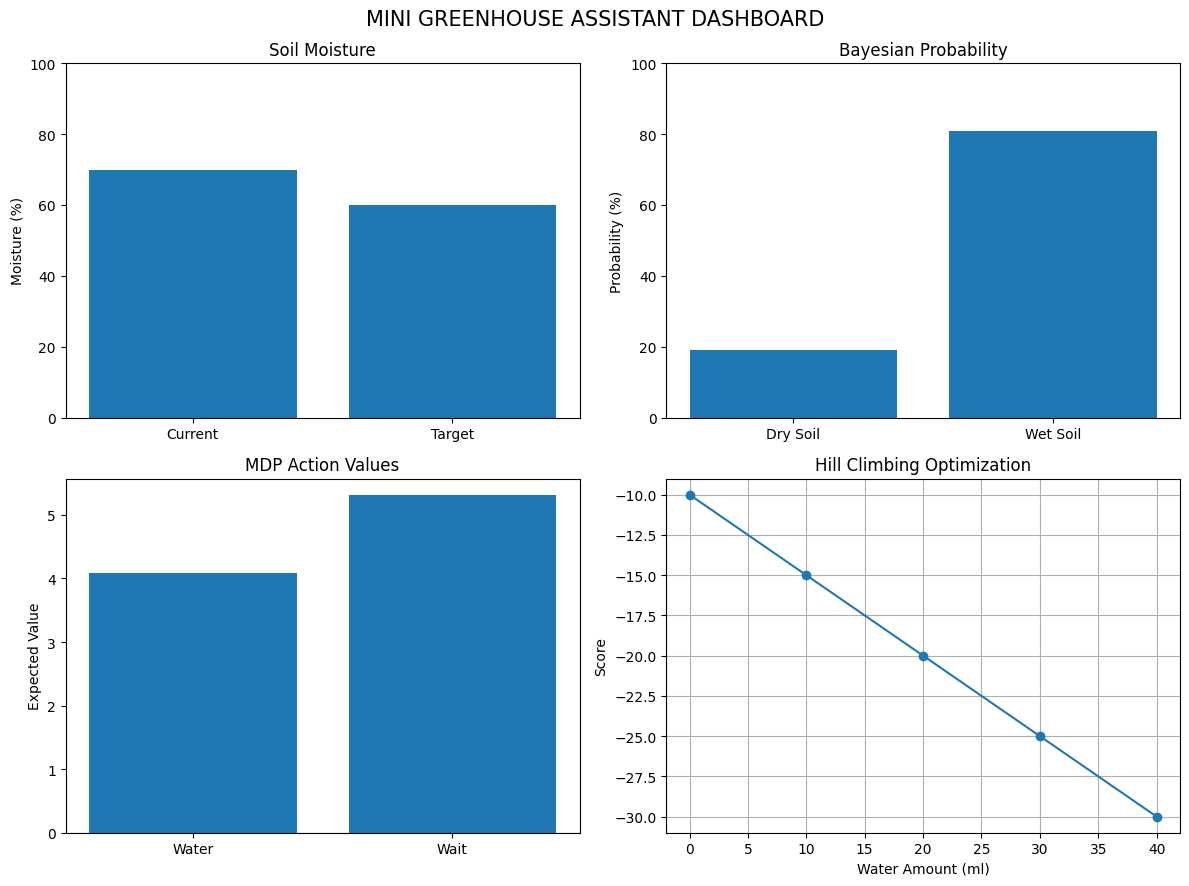

In [16]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].bar(
    ["Current", "Target"],
    [current_moisture, target_moisture]
)
axes[0, 0].set_title("Soil Moisture")
axes[0, 0].set_ylabel("Moisture (%)")
axes[0, 0].set_ylim(0, 100)

axes[0, 1].bar(
    ["Dry Soil", "Wet Soil"],
    [prob_dry * 100, prob_wet * 100]
)
axes[0, 1].set_title("Bayesian Probability")
axes[0, 1].set_ylabel("Probability (%)")
axes[0, 1].set_ylim(0, 100)

axes[1, 0].bar(
    ["Water", "Wait"],
    [water_value, wait_value]
)
axes[1, 0].set_title("MDP Action Values")
axes[1, 0].set_ylabel("Expected Value")
axes[1, 0].axhline(0, linewidth=0.8)

scores = [calculate_score(w) for w in water_options]

axes[1, 1].plot(
    water_options,
    scores,
    marker="o"
)
axes[1, 1].set_title("Hill Climbing Optimization")
axes[1, 1].set_xlabel("Water Amount (ml)")
axes[1, 1].set_ylabel("Score")
axes[1, 1].grid(True)

plt.suptitle("MINI GREENHOUSE ASSISTANT DASHBOARD",
             fontsize=15)

plt.tight_layout()
plt.show()
